In [ ]:
import pandas as pd
def append_csv(source_file, target_file):
    source_data = pd.read_csv(source_file, skiprows = 1)
    target_data = pd.read_csv(target_file, skiprows = 1)

    combined_data = pd.concat([source_data, target_data])
    combined_data.to_csv(target_file, index=False)

# Example usage
# source_file = 'RL_mimo_ofdm/PPO_2ue16Nt_128_estTh/monitor_0.csv'
# target_file = 'RL_mimo_ofdm/PPO_2ue16Nt_128_estTh/monitor.csv'
# append_csv(source_file, target_file)

### Changes
Learning rate scheduling: start with large learning rate and it decreases as training progresses. 

### Changed the data traffic assumptions

- Buffer for $U$ users are $[B_1, \cdots, B_U]$, each with a different finite buffer size. 
- First-in first-out principle.
- The latency constraints, deadlines, of users are $T_1, \cdots, T_U$.
- The arrival probability of packets follow Binomial distribution with different arrival rates $P_{d1}, \cdots, P_{dU}$. 
- A packet is of size 1. 
- Each packet is associated with a waiting time. We define $\delta_1, \cdots, \delta_U$ as the waiting time of the packets that is transmitted at the current TTI. 

- Packet drop:
    - $drop_{l}$: a packet's waiting time is longer than their latency constraints $T$.

    - $drop_{o}$: a user's buffer is full and there is new packet coming.

#### Objective function
This paper considers the cross-layer resource management for ISAC. Incorporating the buffer statues, the BS allocates beams from the codebook for different users. 
At any given TTI, the agent has obtained a historical environment information from the received echo, which implies the quality of the allocated beams. It uses these historical measurements to decide the next beams in an intelligent manner. The goal of the BS is to minimize the transmission latency and the normalized estimation errors.

$$
\underset{}{\text{minimize}} \sum_{u=1}^{U} \delta_u + \sum_{u=1}^U \frac{\epsilon_v}{\Delta_v} + \sum_{u=1}^U \frac{\epsilon_d}{\Delta_d}
$$
$\delta_u$ denotes the latency of the packet that is to be transmitted in each user's buffer, i.e., the packet has the longest latency. 

### Actions:
To decrease the action space dimension, we reverted the action space to be as the conference version. 

- a = 0, the beams stay the same
- a = 1, select the best beam from the previously-allocated multiple beams
- a = 2, sweep the beams to the left, select the 3 adjacent beams on the left of the previously-allocated beams 
- a = 3, sweep the beams to the right, select the 3 adjacent beams on the right of the previously-allocated beams 

*Note*: Beams are not reused. For a user, if the allocated beams are already used, the agent searches the closest unused beam.  


#### Reward calculation
The reward is calculated as 
- Transmission reward: the earlier the transmission, the higher the reward
$\sum_{u=1}^{U} T_u - \delta_u$
If there is no packet transmitted by a user, its transmission reward is 0.

- Sensing reward: 
    1. If a user has a packet to transmit at the current TTI, the requirement on the sensing performance is lower.
    estimation_Range $\epsilon_r$ < 0.5, estimation_velocity $\epsilon_v$ < 0.2 
    
    2. If there is no packet to transmit at the current TTI,
    estimation_Range $\epsilon_r$ < 0.2, estimation_velocity $\epsilon_v$ < 0.08

$reward = \sum_{u=1}^{U} (T_u - \delta_u) + \sum_{\text{u~has~a packet}} \mathbb{1}(\epsilon_r < 0.5) + \mathbb{1}(\epsilon_v < 0.2) + \sum_{\text{u~has~no packet}} \mathbb{1}(\epsilon_r < 0.2) + \mathbb{1}(\epsilon_v < 0.08) - drop_l - drop_o$ 


**Benchmark**
- Estimated AoD: The BS estimates the AoDs using MUSIC algorithm based on the reflected echoes. 
Then, the BS best beams to users according to these estimated AoDs.

- Random: One beam is randomly allocated to a user.

**Comparison of reward**
The benchmark of Estimated AoDs is even worse than the begining of the PPO training. 
- Reason: Estimated AoD method only allocates one beam to a user, this will often lead to a bad estimation performance, which is captured by the reward calculation.

---

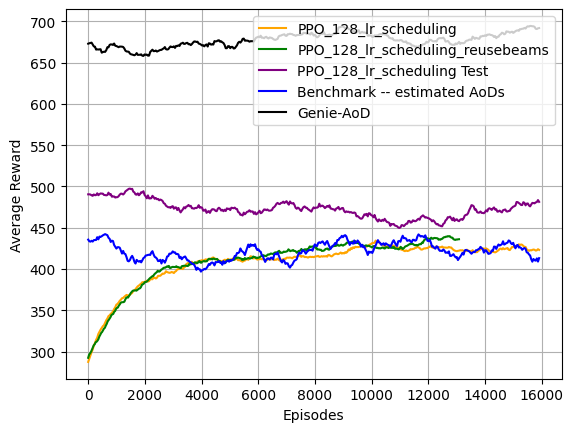

In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
log_dir = 'RL_mimo_ofdm/PPO_2ue16Nt_sAs_newB_waitT_newSense_128_lrscheduling/'
monitor_file = log_dir + "monitor.csv"
# MONITOR_95 is temporary file for testing. It is still running
monitor_data = pd.read_csv(monitor_file, skiprows=0)

window_size = 1000
moving_average = monitor_data['r'].rolling(window=window_size).mean().dropna()

fd_trained = log_dir +'trained/'
trained_reward = pd.read_csv(fd_trained + 'reward.csv', skiprows=0)
tr = trained_reward['Reward'].rolling(window = 100).mean()

fd_genie = log_dir +'genie/'
genie_reward = pd.read_csv(fd_genie + 'reward.csv', skiprows=0)
gr = genie_reward['Reward'].rolling(window = 100).mean()


fd_estimated = log_dir +'estimated/'
benchmark_reward = pd.read_csv(fd_estimated + 'reward.csv', skiprows=0)
br = benchmark_reward['Reward'].rolling(window = 100).mean()
br_length = len(br.dropna())

selected_values = moving_average[::len(moving_average)//br_length][:(br_length)]

monitor_file_reusebeams = 'RL_mimo_ofdm/PPO_2ue16Nt_sAs_newB_waitT_newSense_128_reusebeams/monitor.csv'
monitor_data_reusebeams = pd.read_csv(monitor_file_reusebeams, skiprows=0)
window_size_reusebeams = 1000
moving_average_reusebeams = monitor_data_reusebeams['r'].rolling(window=window_size_reusebeams).mean().dropna()
selected_values_reusebeams = moving_average_reusebeams[::len(moving_average_reusebeams)//br_length][:(br_length)]

# fd_random = log_dir +'random/'
# random_reward = pd.read_csv(fd_random + 'reward.csv', skiprows=0)
# rr = random_reward['Reward'].rolling(window = 100).mean()


fig, ax = plt.subplots()
ax.plot(np.linspace(0, len(moving_average), br_length), selected_values.dropna(), label='PPO_128_lr_scheduling', color='orange')
ax.plot(np.linspace(0, len(moving_average_reusebeams), br_length), selected_values_reusebeams.dropna(), label='PPO_128_lr_scheduling_reusebeams', color='green')
ax.plot(np.linspace(0, len(moving_average), br_length), tr.dropna(), label='PPO_128_lr_scheduling Test', color='purple')
ax.plot(np.linspace(0, len(moving_average), br_length), br.dropna(), label='Benchmark -- estimated AoDs', color='blue')
ax.plot(np.linspace(0, len(moving_average), br_length), gr.dropna(), label='Genie-AoD', color='black')
# ax.plot(np.linspace(0, len(moving_average), br_length), rr.dropna(), label='Random', color='red')

ax.legend(loc='upper right')
ax.grid()
ax.set_xlabel('Episodes')
ax.set_ylabel('Average Reward')

plt.show()

**Communication -- Latency**

The following figure evaluates the probability of waiting time for a **transmitted** packet for different methods.

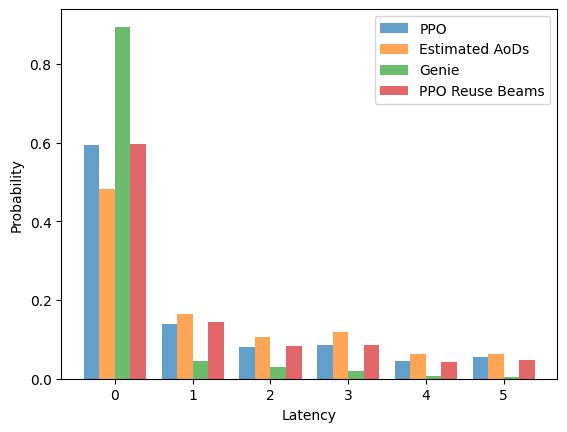

In [6]:
import matplotlib.pyplot as plt
import itertools
import pandas as pd

def load_latency(log_dir, filename):
    data = pd.read_csv(log_dir + filename, skiprows=0)
    data1 = list(itertools.chain(*data.values))
    data2 = [x for x in data1 if x != -1]
    return data2

latency_trained = load_latency(fd_trained, 'latency.csv')
latency_benchmark = load_latency(fd_estimated, 'latency.csv')

latency_genie = load_latency(fd_genie , 'latency.csv')
# latency_r = load_latency(fd_random , 'latency.csv')

latency_reusebeams = load_latency('RL_mimo_ofdm/PPO_2ue16Nt_sAs_newB_waitT_newSense_128_reusebeams/trained/', 'latency.csv')

#
figure_handle = plt.figure()
ax2 = figure_handle.add_subplot()

counts_trained, bins_trained, patches_trained = ax2.hist(latency_trained, bins=range(7), density=True, alpha=0.7, label='PPO')
counts_benchmark, bins_benchmark, patches_benchmark = ax2.hist(latency_benchmark, bins=range(7), density=True, alpha=0.7, label='Estimated AoD')
counts_genie, bins_genie, patches_genie = ax2.hist(latency_genie, bins=range(7), density=True, alpha=0.7, label='Genie')
# counts_random, bins_random, patches_random = ax2.hist(latency_random, bins=range(7), density=True, alpha=0.7, label='Random')
counts_reusebeams, bins_reusebeams, patches_reusebeams = ax2.hist(latency_reusebeams, bins=range(7), density=True, alpha=0.7, label='PPO Reuse Beams')

bin_centers = 0.5 * (bins_trained[:-1] + bins_trained[1:])

ax2.cla()  # Clear the previous plot
ax2.bar(bin_centers - 0.3, counts_trained, width=0.2, align='center', alpha=0.7, label='PPO')
ax2.bar(bin_centers - 0.1, counts_benchmark, width=0.2, align='center', alpha=0.7, label='Estimated AoDs')
ax2.bar(bin_centers+0.1, counts_genie, width=0.2, align='center', alpha=0.7, label='Genie')
# ax2.bar(bin_centers+0.3, counts_random, width=0.2, align='center', alpha=0.7, label='Random')
ax2.bar(bin_centers + 0.3, counts_reusebeams, width=0.2, align='center', alpha=0.7, label='PPO Reuse Beams')

ax2.set_xticks(bin_centers)

ax2.set_xticks(bin_centers)
ax2.set_xticklabels(range(6))
ax2.set_xlabel('Latency')
ax2.set_ylabel('Probability')
ax2.legend()


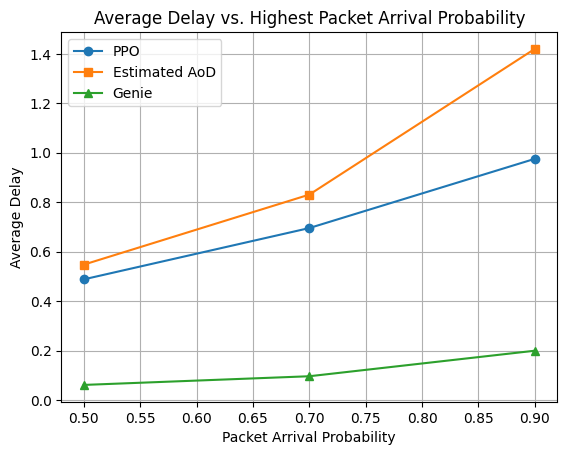

In [18]:
fd_trained_05 = 'RL_mimo_ofdm/PPO_2ue16Nt_sAs_newB_waitT_sense_ce-2/trained_05/'
fd_estimated_05 = 'RL_mimo_ofdm/PPO_2ue16Nt_sAs_newB_waitT_sense_ce-2/estimated_05/'
fd_genie_05 = 'RL_mimo_ofdm/PPO_2ue16Nt_sAs_newB_waitT_sense_ce-2/genie_05/'
fd_trained_07 = 'RL_mimo_ofdm/PPO_2ue16Nt_sAs_newB_waitT_sense_ce-2/trained_07/'
fd_estimated_07 = 'RL_mimo_ofdm/PPO_2ue16Nt_sAs_newB_waitT_sense_ce-2/estimated_07/'
fd_genie_07 = 'RL_mimo_ofdm/PPO_2ue16Nt_sAs_newB_waitT_sense_ce-2/genie_07/'


latency_t_09 = pd.read_csv(fd_trained + 'latency.csv', skiprows=0)
latency_b_09 = pd.read_csv(fd_estimated + 'latency.csv', skiprows=0)
latency_g_09 = pd.read_csv(fd_genie + 'latency.csv', skiprows=0)

latency_t_05 = pd.read_csv(fd_trained_05 + 'latency.csv', skiprows=0)
latency_b_05 = pd.read_csv(fd_estimated_05 + 'latency.csv', skiprows=0)
latency_g_05 = pd.read_csv(fd_genie_05 + 'latency.csv', skiprows=0)

latency_t_07 = pd.read_csv(fd_trained_07 + 'latency.csv', skiprows=0)
latency_b_07 = pd.read_csv(fd_estimated_07 + 'latency.csv', skiprows=0)
latency_g_07 = pd.read_csv(fd_genie_07 + 'latency.csv', skiprows=0)
import itertools
import numpy as np

latency_trained_09 = list(itertools.chain(*latency_t_09.values))
latency_benchmark_09 = list(itertools.chain(*latency_b_09.values))
latency_genie_09 = list(itertools.chain(*latency_g_09.values))

latency_trained_05 = list(itertools.chain(*latency_t_05.values))
latency_benchmark_05 = list(itertools.chain(*latency_b_05.values))
latency_genie_05 = list(itertools.chain(*latency_g_05.values))
latency_trained_07 = list(itertools.chain(*latency_t_07.values))
latency_benchmark_07 = list(itertools.chain(*latency_b_07.values))
latency_genie_07 = list(itertools.chain(*latency_g_07.values))

latency_trained_09 = [x for x in latency_trained_09 if x != -1]
latency_benchmark_09 = [x for x in latency_benchmark_09 if x != -1]
latency_genie_09 = [x for x in latency_genie_09 if x != -1]
latency_trained_05 = [x for x in latency_trained_05 if x != -1]
latency_benchmark_05 = [x for x in latency_benchmark_05 if x != -1]
latency_genie_05 = [x for x in latency_genie_05 if x != -1]
latency_trained_07 = [x for x in latency_trained_07 if x != -1]
latency_benchmark_07 = [x for x in latency_benchmark_07 if x != -1]
latency_genie_07 = [x for x in latency_genie_07 if x != -1]

counts_trained = np.zeros([6,3])
counts_benchmark = np.zeros([6,3])
counts_genie = np.zeros([6,3])

counts_trained[:,2], _, _ = ax2.hist(latency_trained_09, bins=range(7), density=True, alpha=0.7, label='PPO')
counts_benchmark[:,2], _, _ = ax2.hist(latency_benchmark_09, bins=range(7), density=True, alpha=0.7, label='Estimated AoD')
counts_genie[:,2], _, _ = ax2.hist(latency_genie_09, bins=range(7), density=True, alpha=0.7, label='Genie')

counts_trained[:,0], _, _ = ax2.hist(latency_trained_05, bins=range(7), density=True, alpha=0.7, label='PPO')
counts_benchmark[:,0], _, _ = ax2.hist(latency_benchmark_05, bins=range(7), density=True, alpha=0.7, label='Estimated AoD')
counts_genie[:,0], _, _ = ax2.hist(latency_genie_05, bins=range(7), density=True, alpha=0.7, label='Genie')

counts_trained[:,1], _, _ = ax2.hist(latency_trained_07, bins=range(7), density=True, alpha=0.7, label='PPO')
counts_benchmark[:,1], _, _ = ax2.hist(latency_benchmark_07, bins=range(7), density=True, alpha=0.7, label='Estimated AoD')
counts_genie[:,1], _, _ = ax2.hist(latency_genie_07, bins=range(7), density=True, alpha=0.7, label='Genie')
# Calculate average delays
ave_delay_trained = np.dot(range(6), counts_trained)
ave_delay_estimated = np.dot(range(6), counts_benchmark)
ave_delay_genie = np.dot(range(6), counts_genie)

import matplotlib.pyplot as plt

fig, ax = plt.subplots()
arrival_prob = [0.5, 0.7, 0.9]

ax.plot(arrival_prob, ave_delay_trained, marker='o', label='PPO')
ax.plot(arrival_prob, ave_delay_estimated, marker='s', label='Estimated AoD')
ax.plot(arrival_prob, ave_delay_genie, marker='^', label='Genie')

ax.set_xlabel('Packet Arrival Probability')
ax.set_ylabel('Average Delay')
ax.set_title('Average Delay vs. Highest Packet Arrival Probability')
ax.legend()
ax.grid(True)
plt.show()


The above figure shows the averaged delay of packets as a function of packet arrival probability.
When the packet arrival probability is higher, the gain of PPO is bigger. This implies that the cross-layer resource management is helpful. 

**Communication -- spectral efficiency**

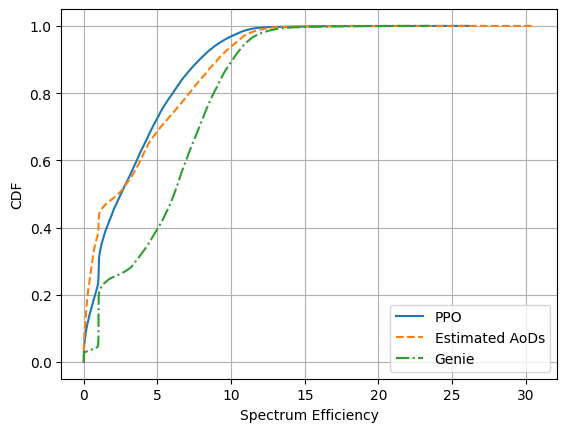

In [9]:
se_trained = pd.read_csv(fd_trained + 'SE.csv', skiprows=0)
se_benchmark = pd.read_csv(fd_estimated + 'SE.csv', skiprows=0)
se_genie = pd.read_csv(fd_genie+'SE.csv', skiprows=0)
# se_random = pd.read_csv(fd_random + 'SE.csv', skiprows=0)

spectrum_efficiency_trained = list(itertools.chain(*se_trained.values))
spectrum_efficiency_benchmark = list(itertools.chain(*se_benchmark.values))
spectrum_efficiency_genie = list(itertools.chain(*se_genie.values))
# spectrum_efficiency_random = list(itertools.chain(*se_random.values))

figure_handle = plt.figure()
ax = figure_handle.add_subplot()
se_cdf = np.sort(spectrum_efficiency_trained)
yvals = np.arange(len(se_cdf))/float(len(se_cdf)-1)
ax.plot(se_cdf, yvals, '-', label='PPO')

se_cdf = np.sort(spectrum_efficiency_benchmark)
yvals = np.arange(len(se_cdf))/float(len(se_cdf)-1)
ax.plot(se_cdf, yvals, '--', label='Estimated AoDs')

se_cdf = np.sort(spectrum_efficiency_genie)
yvals = np.arange(len(se_cdf))/float(len(se_cdf)-1)
ax.plot(se_cdf, yvals, '-.', label='Genie')

# se_cdf = np.sort(spectrum_efficiency_random)
# yvals = np.arange(len(se_cdf))/float(len(se_cdf)-1)
# ax.plot(se_cdf, yvals, ':', label='Random')

ax.set_xlabel('Spectrum Efficiency')
ax.set_ylabel('CDF')
ax.legend()
ax.grid()

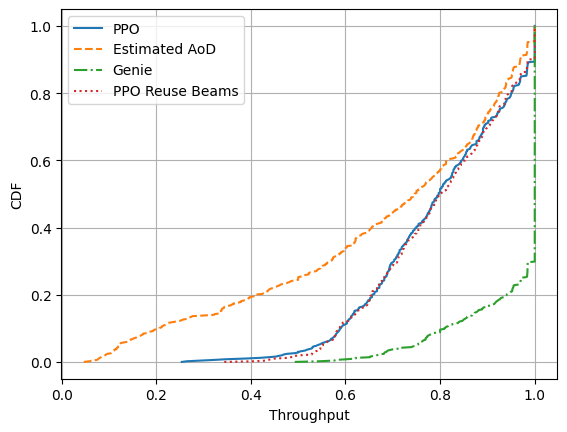

In [ ]:
def cdf_gen(log_dir, filename, item):
    data = pd.read_csv(log_dir + filename, skiprows=0)
    cdf = np.sort(data[item])
    yvals = np.arange(len(cdf))/float(len(cdf)-1)
    return cdf, yvals

#### Throughput CDF ####

figure_handle = plt.figure()
ax = figure_handle.add_subplot()

thp_cdf, yvals = cdf_gen(fd_trained, 'throughput.csv', 'Throughput')
ax.plot(thp_cdf, yvals, '-', label='PPO')

thp_cdf, yvals = cdf_gen(fd_estimated, 'throughput.csv', 'Throughput')
ax.plot(thp_cdf, yvals, '--', label='Estimated AoD')

thp_cdf, yvals = cdf_gen(fd_genie, 'throughput.csv', 'Throughput')
ax.plot(thp_cdf, yvals, '-.', label='Genie')

thp_cdf, yvals = cdf_gen('RL_mimo_ofdm/PPO_2ue16Nt_sAs_newB_waitT_newSense_128_reusebeams/trained/', 'throughput.csv', 'Throughput')
ax.plot(thp_cdf, yvals, ':', label='PPO Reuse Beams')

ax.legend()
ax.set_xlabel('Throughput')
ax.set_ylabel('CDF')
ax.grid()

**Sensing -- Estimation performance**
The estimation performance of range, speed, and angle are affected by the number of subcarriers, the number of OFDM symbols, and the number of antennas,respectively.

Let us define the range bin, speed bin and angle bin as

$$
\Delta_d = \frac{c}{2N_c \Delta f}, ~~ \Delta_v = \frac{c}{2f_c N_s T}, ~~ \Delta_a = \frac{\pi}{N_r}
$$.

Therefore, the normalized error are defined with respect to these bins.

For estimation of range and speed (the following two figures), PPO performs **worse** compared to the benchmark.

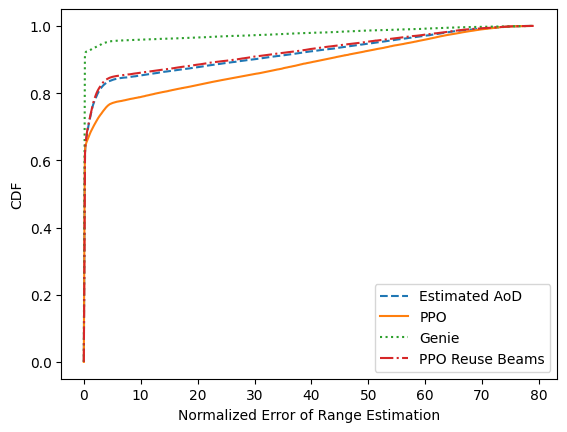

In [ ]:
#### CDF of estimation error ####
# range estimation
er_t = pd.read_csv(fd_trained + 'nmseR_allsteps.csv', skiprows=1)
er_b = pd.read_csv(fd_estimated + 'nmseR_allsteps.csv', skiprows=1)
# er_r = pd.read_csv(fd_random + 'nmseR_allsteps.csv', skiprows=1)
er_g = pd.read_csv(fd_genie + 'nmseR_allsteps.csv', skiprows=1)

figure_handle = plt.figure()
ax3 = figure_handle.add_subplot()
er_benchmark = np.array(er_b)
er_trained = np.array(er_t)
# er_random = np.array(er_r)
er_genie = np.array(er_g)
    
temp = er_benchmark.flatten()
er_cdf = np.sort(temp)
yvals = np.arange(len(er_cdf))/float(len(er_cdf)-1)
ax3.plot(er_cdf, yvals, '--', label='Estimated AoD')

temp = er_trained.flatten()
er_cdf = np.sort(temp)
yvals = np.arange(len(er_cdf))/float(len(er_cdf)-1)
ax3.plot(er_cdf, yvals, '-', label='PPO')

# temp = er_random.flatten()
# er_cdf = np.sort(temp)
# yvals = np.arange(len(er_cdf))/float(len(er_cdf)-1)
# ax3.plot(er_cdf, yvals, '-.', label='Random')

temp = er_genie.flatten()
er_cdf = np.sort(temp)
yvals = np.arange(len(er_cdf))/float(len(er_cdf)-1)
ax3.plot(er_cdf, yvals, ':', label='Genie')

er_reusebeams = pd.read_csv('RL_mimo_ofdm/PPO_2ue16Nt_sAs_newB_waitT_newSense_128_reusebeams/trained/nmseR_allsteps.csv', skiprows=1)
er_reusebeams = np.array(er_reusebeams)
temp = er_reusebeams.flatten()
er_cdf = np.sort(temp)
yvals = np.arange(len(er_cdf))/float(len(er_cdf)-1)
ax3.plot(er_cdf, yvals, '-.', label='PPO Reuse Beams')

ax3.set_xlabel('Normalized Error of Range Estimation')
ax3.set_ylabel('CDF')
ax3.legend()
plt.show()



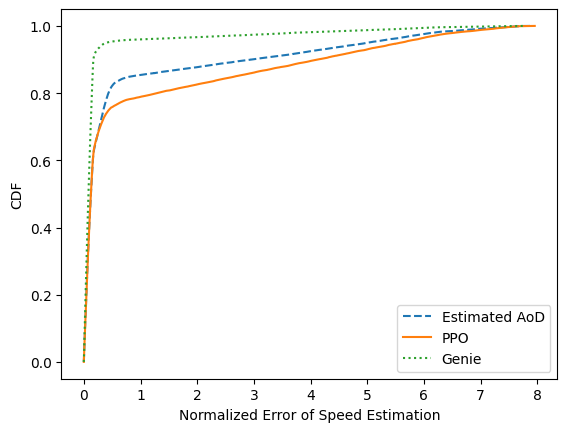

In [13]:
# CDF of speed estimation error
ev_t = pd.read_csv(fd_trained + 'nmseV_allsteps.csv', skiprows=1)
ev_b = pd.read_csv(fd_estimated + 'nmseV_allsteps.csv', skiprows=1)
# ev_r = pd.read_csv(fd_random + 'nmseV_allsteps.csv', skiprows=1)
ev_g = pd.read_csv(fd_genie + 'nmseV_allsteps.csv', skiprows=1)

ev_benchmark = np.array(ev_b)
ev_trained = np.array(ev_t)
# ev_random = np.array(ev_r)
ev_genie = np.array(ev_g)

figure_handle = plt.figure()
ax4 = figure_handle.add_subplot()

temp = ev_benchmark.flatten()
ev_cdf = np.sort(temp)
yvals = np.arange(len(ev_cdf))/float(len(ev_cdf)-1)
ax4.plot(ev_cdf, yvals, '--', label='Estimated AoD')

temp = ev_trained.flatten()
ev_cdf = np.sort(temp)
yvals = np.arange(len(ev_cdf))/float(len(ev_cdf)-1)
ax4.plot(ev_cdf, yvals, '-', label='PPO')

# temp = ev_random.flatten()
# ev_cdf = np.sort(temp)
# yvals = np.arange(len(ev_cdf))/float(len(ev_cdf)-1)
# ax4.plot(ev_cdf, yvals, '-.', label='Random')

temp = ev_genie.flatten()
ev_cdf = np.sort(temp)
yvals = np.arange(len(ev_cdf))/float(len(ev_cdf)-1)
ax4.plot(ev_cdf, yvals, ':', label='Genie')
    
ax4.set_xlabel('Normalized Error of Speed Estimation')
ax4.set_ylabel('CDF')
ax4.legend()
plt.show()

---

##### Several realizations of allocated beams. 

**Genie**:

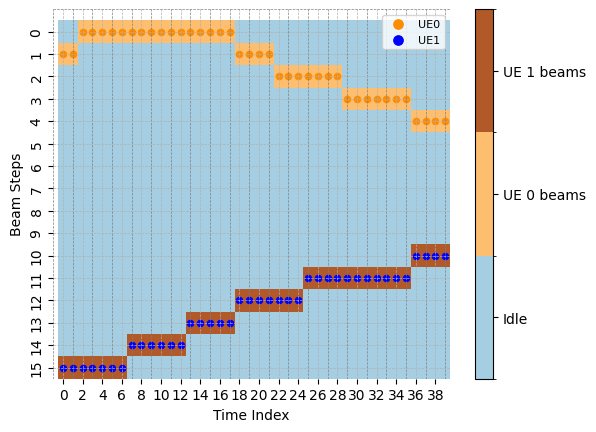

**Estimated AoD**:

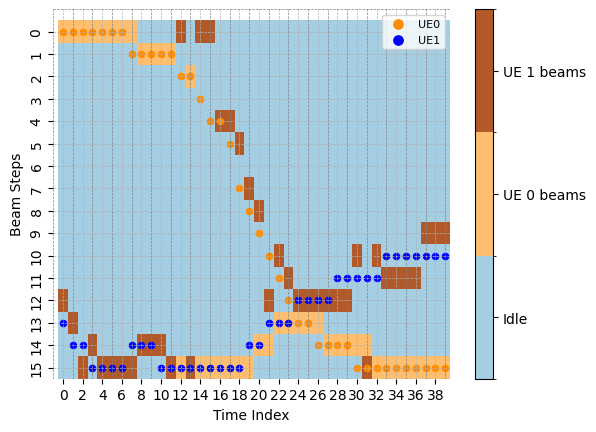

**Trained PPO policy:**

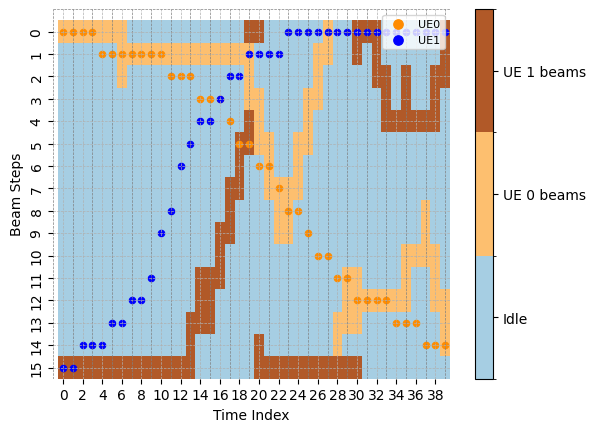
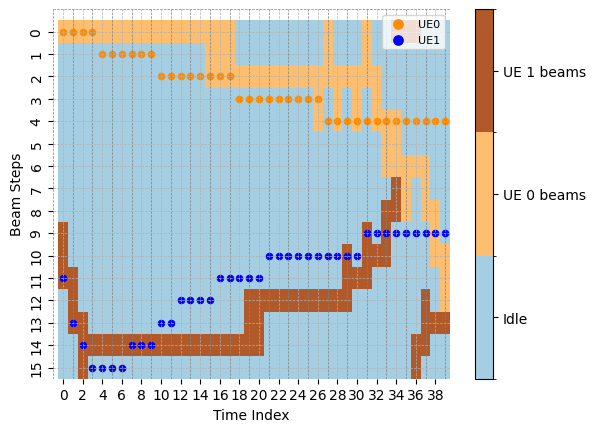
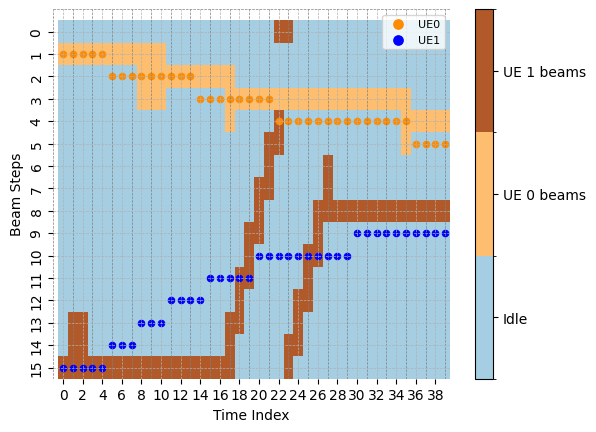

The polciy seems converged to a **suboptimal** point, even though the reward reaches to a plateau.

